# Basic Solution to The Cart-Pole Problem using a Deep Q-Network
![](https://gymnasium.farama.org/_images/cart_pole.gif)

Basic code to implement a Deep Q-Network to solve the Cart-Pole problem is given.

A pole is balancing on a cart which can move left and right.
The only thing the cart can do to balance the pole is apply a fixed force to the left or right.
If the pole hits the ground the cart's family will be killed.
We aid the cart by setting up a simulation to help him practice using the highly limited 3 digit number of neurons his brain has.

Luckily for the cart, this is a well established problem in reinforcement learning, so we can simply import a pre-existing physics simulation of his current unfortunate predicament.

In [1]:
import gymnasium as gym

# For determinism
global_seed = 67

# Initialize the CartPole environment
env = gym.make("CartPole-v1")

# Get the dimensions of the state space and the action space
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

print(f"State space dimension: {state_dim}")
print(f"Action space dimension: {action_dim}")

State space dimension: 4
Action space dimension: 2


Now we create a model of the cart's brain by inheriting `torch.nn.Module`.
He has 4 sensory inputs (state space) relevant to this training simulation:

* His position
* His speed
* The pole's angle relative to him
* The pole's angular velocity

He then has 2 layers of 64 neurons each (shame), and then a final output layer to predict the reward if he applies a force left or applies a force right.



In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(QNetwork, self).__init__()

        # Map from layer 1 to 2: Takes the 4 state variables, outputs to 64 hidden neurons
        self.fc1 = nn.Linear(state_dim, 64)

        # Map from layer 2 to 3: Hidden layer to hidden layer
        self.fc2 = nn.Linear(64, 64)

        # Map from layer 3 to 4: Takes the 64 hidden neurons, outputs the 2 Q-values
        self.fc3 = nn.Linear(64, action_dim)

    def forward(self, state):
        # We use ReLU(x)=max(x,0) activation for the hidden layers
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))

        # No activation function on the final layer because Q-values can theoretically be any real number (positive or negative)
        q_values = self.fc3(x)
        return q_values

Give him a memory of 10000 past experiences.
Once his memory is full he forgets the oldest experience.
To aid in his learning we allow him to recall up to 64 past experiences randomly to learn from in his training.

In [3]:
import random
import numpy as np
from collections import deque

torch.manual_seed(global_seed)
np.random.seed(global_seed)
random.seed(global_seed)

# Define the class
class ReplayBuffer:
    def __init__(self, capacity=10000):
        # deque automatically removes oldest items if capacity is exceeded
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        # Store the 5-tuple experience
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        # Randomly select a batch of experiences
        batch = random.sample(self.buffer, batch_size)

        # Unzip the batch into separate lists/arrays for PyTorch
        states, actions, rewards, next_states, dones = map(np.array, zip(*batch))
        return states, actions, rewards, next_states, dones

    def __len__(self):
        return len(self.buffer)

# Instantiate it
memory = ReplayBuffer(capacity=10000)

In his practice, it is crucial that he explore new strategies every now and then. To do this we use $\epsilon$-greedy action selection.

In [4]:
def select_action(state, q_net, epsilon, action_dim):
    if random.random() < epsilon:
        # Explore: choose a random action
        return random.randrange(action_dim)
    else:
        # Exploit: choose the action with the highest Q-value
        # Convert the numpy state vector into a pytorch tensor
        # Unsqueeze changes the tensor from 1D to 2D
        state_tensor = torch.FloatTensor(state).unsqueeze(0)  # Shape: (1, 4)
        with torch.no_grad():
            q_values = q_net(state_tensor)
        return q_values.argmax().item()

Make a copy of his brain. His main brain is the policy network, and his secondary brain is the target network.
His second brain is kept frozen and only updated (by copying his main brain) every $n$ iterations.
The policy network guesses the action value, the target network (frozen copy) evaluates the actual return of that action, as well as the discounted return of the guess of the next action value.

In [5]:
# Initialize both networks
policy_net = QNetwork(state_dim, action_dim)
target_net = QNetwork(state_dim, action_dim)

# Copy the completely random initial weights from policy to target
target_net.load_state_dict(policy_net.state_dict())

# Set target network to evaluation mode (turns off gradients/training behaviors)
target_net.eval()

QNetwork(
  (fc1): Linear(in_features=4, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=2, bias=True)
)

Setup the loss function. This is a measure of how 'surprised' the policy network is by its action value guess versus the target networks more accurate guess one step in the future.
We aim for the cart to never be surprised by the outcome of an action.

In [6]:
def compute_loss(batch, policy_net, target_net, gamma=0.99):
    # Unpack the batch of experiences
    states, actions, rewards, next_states, dones = batch

    # Convert numpy arrays to PyTorch tensors
    states = torch.FloatTensor(states)
    actions = torch.LongTensor(actions).unsqueeze(1) # Reshape for gather
    rewards = torch.FloatTensor(rewards)
    next_states = torch.FloatTensor(next_states)
    dones = torch.FloatTensor(dones)

    # 1. PREDICTIONS: Get the Q-values from the Policy Network for the actions actually taken
    # .gather() acts like a router, plucking out the exact Q-value for the chosen action
    current_q_values = policy_net(states).gather(1, actions).squeeze(1)

    # 2. TARGETS: Get the maximum Q-values for the next states from the Target Network
    with torch.no_grad():
        # .max(1)[0] gets the highest Q-value across the action dimension
        next_q_values = target_net(next_states).max(1)[0]

    # Calculate the Bellman targets
    target_q_values = rewards + (gamma * next_q_values * (1 - dones))

    # 3. LOSS: Compare them using Mean Squared Error
    loss = F.mse_loss(current_q_values, target_q_values)

    return loss

Use the Adam algorithm to adjust his neuron weights and biases to minimise the loss function.
In simpler terms, we alter his brain to minimise his surprise of the outcome of an action.

In [7]:
# Set up the optimiser
optimizer = torch.optim.Adam(policy_net.parameters(), lr=1e-3)

# Hyperparameters
num_episodes = 500
batch_size = 64
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.990
reward_threshold = 475

Before setting up the main training loop, we create a function to evaluate the cart's training progress.
We set $\epsilon = 0$ to stop exploration, and make the cart only exploit its knowledge.

In [8]:
def run_greedy_episode(use_seed = False):
    if use_seed:
        state, _ = env.reset(seed=global_seed)
    else:
        state, _ = env.reset()

    total_reward = 0
    done = False

    while not done:
        action = select_action(state, policy_net, 0, action_dim)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Not necessary to sync the target network, update memory or train
        state = next_state
        total_reward += reward

    return total_reward

Main training loop.
We fully simulate each episode, adding each experience to memory.
Once enough memories have accrued, we randomly sample a `batch_size` number of memories and optimise the network parameters based on those.

If the reward of one of these episodes is close to perfect, we `run_greedy_episode()` a number of times to verify those network parameters are indeed a solution.
If they are, we stop training.

In [9]:
total_training_steps = 0

for episode in range(num_episodes):
    if episode == 0:
        state, _ = env.reset(seed=global_seed)
    else:
        state, _ = env.reset()

    # Reset to random initial conditions
    total_reward = 0
    done = False

    while not done:
        # Choose the action with the highest predicted immediate reward
        action = select_action(state, policy_net, epsilon, action_dim)
        # Step the physics simulation forward in time to get the actual reward
        next_state, reward, terminated, truncated, _ = env.step(action)
        # If the network fails, or makes it to the end of the 500 iterations, terminate the while loop
        done = terminated or truncated

        # Add the current experience
        memory.push(state, action, reward, next_state, terminated)
        state = next_state
        total_reward += reward

        # Once enough memory has been accrued we sample the memory to make the model learn
        if len(memory) >= 5*batch_size:
            batch = memory.sample(batch_size)
            loss = compute_loss(batch, policy_net, target_net, gamma)

            # Improve the policy network's parameters
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_training_steps += 1
        if total_training_steps % 500 == 0:
            target_net.load_state_dict(policy_net.state_dict())

    # Decay epsilon - reduce the amount of exploration with time to some minimum value
    epsilon = max(epsilon_min, epsilon_decay * epsilon)

    # Log the current approximate training status every few episodes
    if (episode + 1) % 20 == 0:
        print(f"Episode {episode + 1} | Total Reward: {total_reward:.1f} | Epsilon: {epsilon:.2f}")

    # If the reward is greater than some threshold, pause training to verify if the solution is good
    if total_reward >= reward_threshold:
        print(f"Found potential solution at episode {episode + 1}, total reward of {total_reward}")
        # Set epsilon to zero and run n times for testing
        scores = [run_greedy_episode() for _ in range(10)]
        avg_score = np.mean(scores)

        # Stop training if solution is correct
        if avg_score >= reward_threshold:
            print(f"Confirmed solution at episode {episode + 1}, averaging a reward of {avg_score}")
            break

Episode 20 | Total Reward: 10.0 | Epsilon: 0.82
Episode 40 | Total Reward: 9.0 | Epsilon: 0.67
Episode 60 | Total Reward: 25.0 | Epsilon: 0.55
Episode 80 | Total Reward: 17.0 | Epsilon: 0.45
Episode 100 | Total Reward: 79.0 | Epsilon: 0.37
Episode 120 | Total Reward: 120.0 | Epsilon: 0.30
Episode 140 | Total Reward: 146.0 | Epsilon: 0.24
Episode 160 | Total Reward: 171.0 | Epsilon: 0.20
Episode 180 | Total Reward: 11.0 | Epsilon: 0.16
Episode 200 | Total Reward: 121.0 | Epsilon: 0.13
Episode 220 | Total Reward: 108.0 | Epsilon: 0.11
Episode 240 | Total Reward: 24.0 | Epsilon: 0.09
Episode 260 | Total Reward: 110.0 | Epsilon: 0.07
Episode 280 | Total Reward: 108.0 | Epsilon: 0.06
Episode 300 | Total Reward: 22.0 | Epsilon: 0.05
Episode 320 | Total Reward: 116.0 | Epsilon: 0.04
Episode 340 | Total Reward: 125.0 | Epsilon: 0.03
Episode 360 | Total Reward: 111.0 | Epsilon: 0.03
Episode 380 | Total Reward: 139.0 | Epsilon: 0.02
Found potential solution at episode 388, total reward of 500.0


Now we verify if the cart has learned enough to save his family's life.
We stop exploration by greedily choosing the best action according to the network's approximation of $Q(s,a)$, with $\epsilon = 0$.

In [10]:
n_evals = 100
eval_rewards = np.zeros(n_evals)

for eval_episode in range(n_evals):
    total_reward = run_greedy_episode(eval_episode == 0)
    eval_rewards[eval_episode] = total_reward

avg_reward = np.mean(eval_rewards)
std_reward = np.std(eval_rewards)

print(f"Average reward over {n_evals} evaluations: {avg_reward:.2f}")
print(f"Standard deviation of rewards: {std_reward:.2f}")

env.close()

Average reward over 100 evaluations: 500.00
Standard deviation of rewards: 0.00


The cart is ready to be tested to save his family's life.
His training was successful.

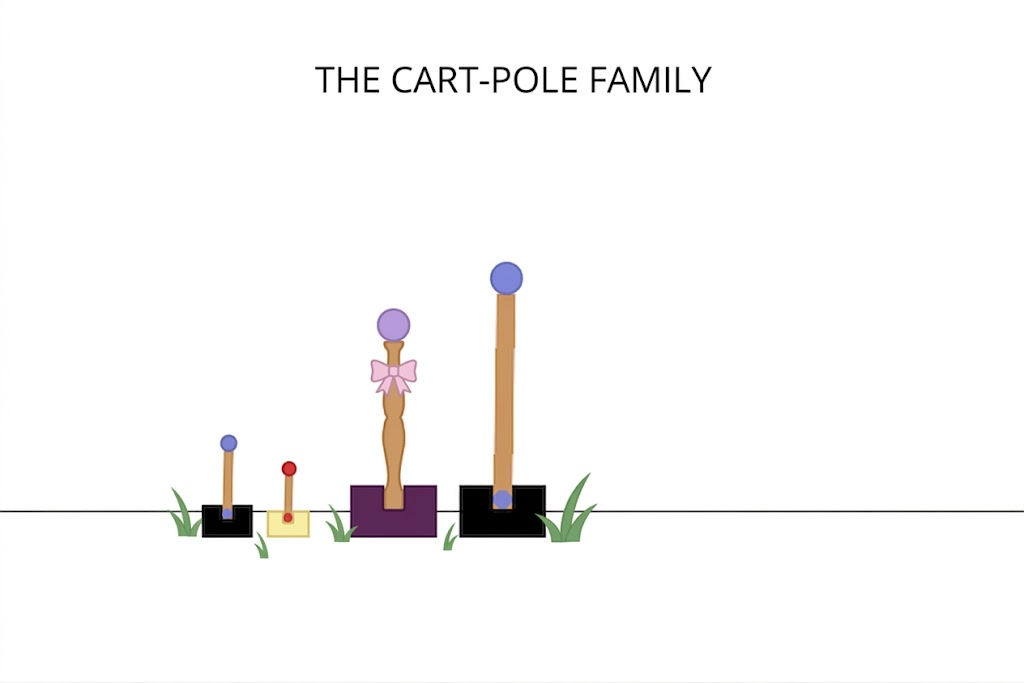